In [658]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from scikeras.wrappers import KerasRegressor


from sklearn.metrics import mean_absolute_error

In [659]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [660]:
# Fix random state
random_state = 42

In [661]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [662]:
apogee = apogee[apogee.parallax >2]
print (len(apogee))
galah = galah[galah.parallax > 3]
print (len(galah))


23511
19678


# Here we focus on getting Fe from no abundance

In [663]:
columns_for_Fe = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', # 'parallax',  #'pmra', 'pmdec', #'ra', 'dec',
                'fe_h', ]

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [664]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    return X

#apogee = fit_trasform(apogee)
#harps = fit_trasform(harps)
#galah = fit_trasform(galah)
#gr8 = fit_trasform(gr8)

### Identifying and exluding null values

In [665]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [666]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [667]:
#gr8.isnull().sum() # No null values

In [668]:
#harps.isnull().sum() # No null values

### Spliting data into Trianing and Testing sets

In [669]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train, X_gr8], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train, y_gr8], ignore_index=True)


In [670]:
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)



model_names = {
    'xgbr': xgbr,
    'lgbr': lgbr,
}


In [671]:

def uniform_sample_by_target(X, y, n_bins=10, samples_per_bin=1000, random_state=42):
    # Combine into one DataFrame
    df = X.copy()
    df['target'] = y

    # Bin the target
    df['target_bin'] = pd.qcut(df['target'], q=n_bins, duplicates='drop')

    # Determine how many samples per bin
    bin_counts = df['target_bin'].value_counts().sort_index()
    if samples_per_bin is None:
        samples_per_bin = bin_counts.min()

    # Sample uniformly across bins
    df_balanced = df.groupby('target_bin', group_keys=False).apply(
        lambda g: g.sample(n=min(len(g), samples_per_bin), random_state=random_state)
    )

    # Separate X and y again
    y_balanced = df_balanced['target']
    X_balanced = df_balanced.drop(columns=['target', 'target_bin'])

    return X_balanced, y_balanced

X_bal, y_bal = uniform_sample_by_target(X_combined_train, y_combined_train, n_bins=10)


/tmp/ipykernel_38876/2273948186.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_balanced = df.groupby('target_bin', group_keys=False).apply(
/tmp/ipykernel_38876/2273948186.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = df.groupby('target_bin', group_keys=False).apply(


In [672]:
def uniform_sample_by_target_range(X, y, bin_edges, samples_per_bin=None, random_state=42):
    df = X.copy()
    df['target'] = y

    # Bin target by value ranges
    df['target_bin'] = pd.cut(df['target'], bins=bin_edges)

    # Determine min count if not specified
    bin_counts = df['target_bin'].value_counts().sort_index()
    if samples_per_bin is None:
        samples_per_bin = bin_counts.min()

    # Sample uniformly across bins
    df_balanced = df.groupby('target_bin', group_keys=False).apply(
        lambda g: g.sample(n=min(len(g), samples_per_bin), random_state=random_state)
    )

    # Separate X and y
    y_balanced = df_balanced['target']
    X_balanced = df_balanced.drop(columns=['target', 'target_bin'])

    return X_balanced, y_balanced


bin_edges = [-1.0, -0.-0.8, -0.6, -0.4, -0.25, 0.0, 0.25, 0.5]
X_bal_by_range, y_bal_by_range  = uniform_sample_by_target_range(X_combined_train, y_combined_train, bin_edges, samples_per_bin = 1000)



/tmp/ipykernel_38876/3860896920.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_balanced = df.groupby('target_bin', group_keys=False).apply(
/tmp/ipykernel_38876/3860896920.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = df.groupby('target_bin', group_keys=False).apply(


In [673]:
def uniform_sample_by_target_range_oversample(X, y, bin_edges, samples_per_bin=None, random_state=42):
    df = X.copy()
    df['target'] = y
    df['target_bin'] = pd.cut(df['target'], bins=bin_edges)

    # Determine default number of samples per bin
    bin_counts = df['target_bin'].value_counts().sort_index()
    if samples_per_bin is None:
        samples_per_bin = bin_counts.max()

    balanced_samples = []

    for bin_interval, group in df.groupby('target_bin'):
        n_samples = len(group)
        if n_samples < samples_per_bin:
            # Oversample with replacement
            sampled = group.sample(n=samples_per_bin, replace=True, random_state=random_state)
        else:
            # Undersample without replacement
            sampled = group.sample(n=samples_per_bin, replace=False, random_state=random_state)
        balanced_samples.append(sampled)

    df_balanced = pd.concat(balanced_samples)

    # Separate X and y again
    y_balanced = df_balanced['target']
    X_balanced = df_balanced.drop(columns=['target', 'target_bin'])

    return X_balanced, y_balanced


bin_edges = [-1.0, -0.-0.8, -0.6, -0.4, -0.25, 0.0, 0.25, 0.5]
X_bal_by_range_oversample, y_bal_by_range_oversample  = uniform_sample_by_target_range_oversample(X_combined_train, y_combined_train, bin_edges, samples_per_bin = 1000)


/tmp/ipykernel_38876/632989060.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin_interval, group in df.groupby('target_bin'):


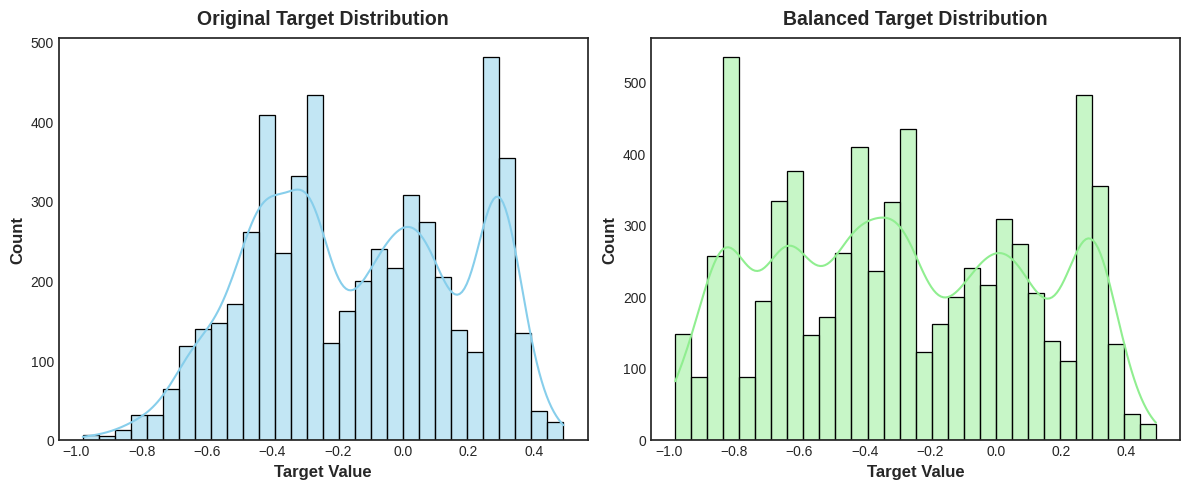

In [674]:

def plot_target_distributions(y_original, y_balanced, bins=30):
    plt.figure(figsize=(12, 5))

    # Original distribution
    plt.subplot(1, 2, 1)
    sns.histplot(y_original, bins=bins, kde=True, color='skyblue')
    plt.title('Original Target Distribution')
    plt.xlabel('Target Value')
    plt.ylabel('Count')

    # Balanced distribution
    plt.subplot(1, 2, 2)
    sns.histplot(y_balanced, bins=bins, kde=True, color='lightgreen')
    plt.title('Balanced Target Distribution')
    plt.xlabel('Target Value')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()

# Run the plot function
plot_target_distributions(y_bal_by_range, y_bal_by_range_oversample)


In [675]:
import pandas as pd

# Before
print("Original target distribution:")
print(pd.qcut(y_combined_train, q=10, duplicates='drop').value_counts().sort_index())

# After
print("\nBalanced target distribution:")
print(pd.qcut(y_bal, q=10, duplicates='drop').value_counts().sort_index())
print(pd.qcut(y_bal_by_range, q=10, duplicates='drop').value_counts().sort_index())
print(pd.qcut(y_bal_by_range_oversample, q=10, duplicates='drop').value_counts().sort_index())



Original target distribution:
fe_h
(-0.981, -0.3]    3800
(-0.3, -0.2]      3499
(-0.2, -0.12]     4089
(-0.12, -0.07]    3694
(-0.07, -0.03]    3354
(-0.03, 0.01]     3449
(0.01, 0.06]      4048
(0.06, 0.11]      3320
(0.11, 0.19]      3608
(0.19, 0.54]      3502
Name: count, dtype: int64

Balanced target distribution:
target
(-0.961, -0.291]    1000
(-0.291, -0.192]    1000
(-0.192, -0.113]    1000
(-0.113, -0.064]    1000
(-0.064, -0.025]    1000
(-0.025, 0.014]     1000
(0.014, 0.063]      1000
(0.063, 0.112]      1000
(0.112, 0.191]      1000
(0.191, 0.49]       1000
Name: count, dtype: int64
target
(-0.981, -0.54]    551
(-0.54, -0.43]     583
(-0.43, -0.35]     492
(-0.35, -0.27]     603
(-0.27, -0.14]     482
(-0.14, -0.03]     535
(-0.03, 0.07]      565
(0.07, 0.22]       513
(0.22, 0.3]        613
(0.3, 0.49]        454
Name: count, dtype: int64
target
(-0.981, -0.82]    821
(-0.82, -0.66]     633
(-0.66, -0.55]     670
(-0.55, -0.42]     714
(-0.42, -0.3]      729
(-0.3, -0.

In [676]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [677]:
# Evaluate on HARPS test
results_harps = evaluate_on_test_data(
    X_bal_by_range_oversample, y_bal_by_range_oversample,
    test_df=harps,
    target='fe_h',
    models=model_names,
    test_name='HARPS'
)


Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.189 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.177 (mean baseline: 0.204)



In [678]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


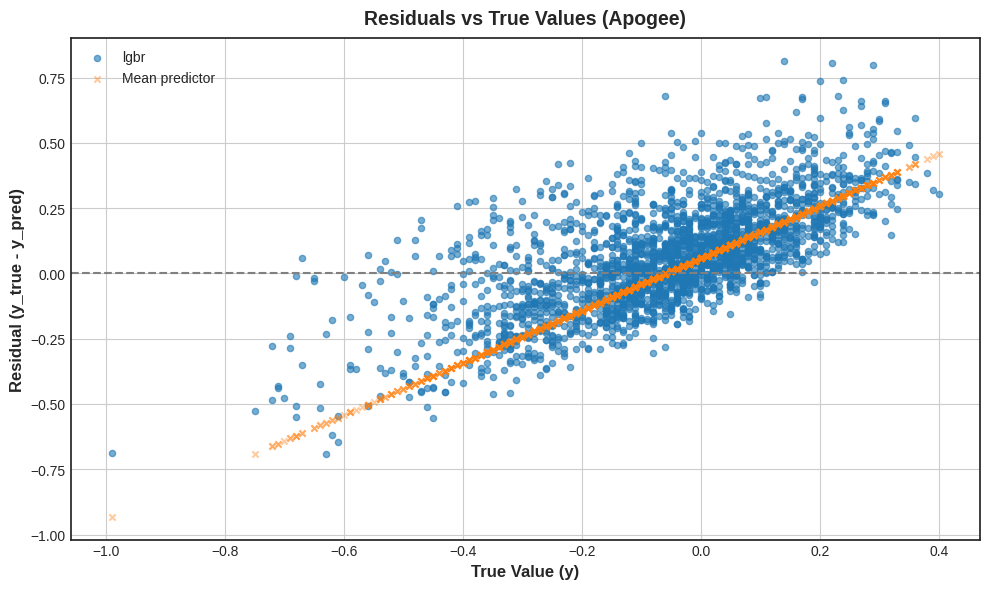

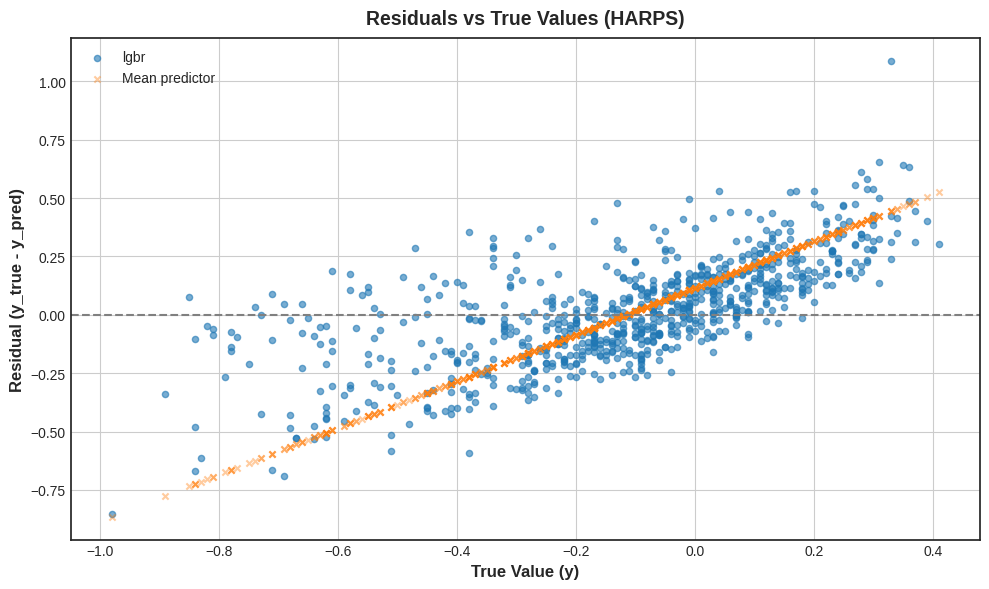

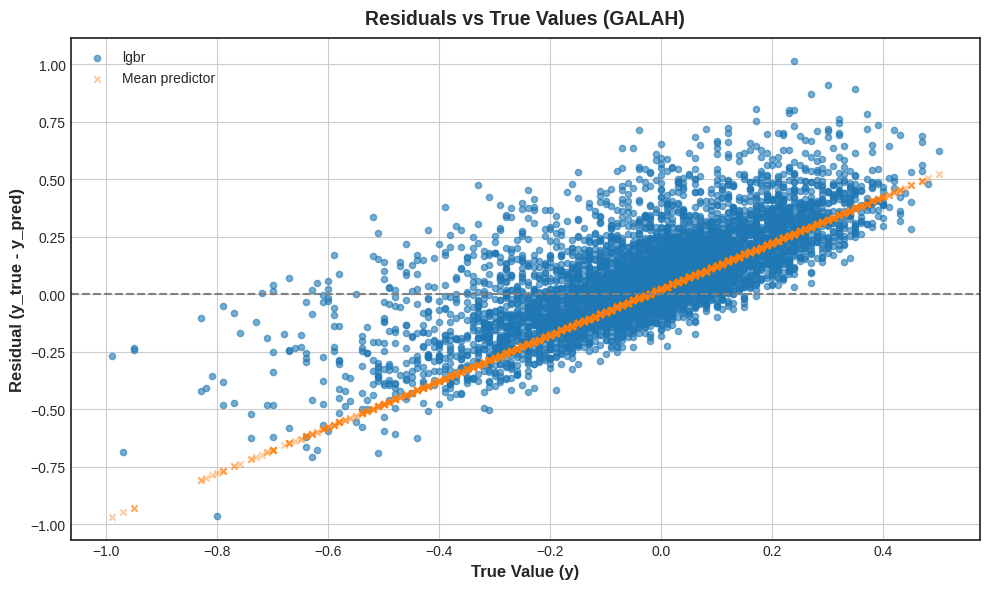

In [681]:
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
model.fit(X_bal_by_range_oversample, y_bal_by_range_oversample)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

y_pred_galah = model.predict(X_galah_test)
plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')
